# Solar filament instance segmentation: full pipeline

Solar Filament Segmentation Challenge 2026 (IEEE BigData Cup). Input: GONG H-alpha full-disk images (2048 × 2048).
Output: one mask per filament.

| Step | Method |
|---|---|
| Preprocessing | Fit the solar disk, divide by the limb-darkening profile, 3 input planes |
| Models | U-Net with EfficientNet-B3 encoder; 2 families × 5 date-grouped folds: BCE + Tversky loss, and BCE + Tversky + BiCC component loss |
| Inference | 512 px tiles, 4-way flip/rotation TTA, mean of the 5 folds per family, mean of the 2 families |
| Post-processing | Permissive candidates → gradient-boosted rescorer keeps or drops each candidate → keep the p > 0.5 core of each kept filament |

The notebook runs from the repository root or from `notebooks/`. The method code is in `src/filament`.

## 1. Configuration

`TRAIN` selects the training mode:
- `"release"`: download the 10 trained models and their out-of-fold maps (fast).
- `"smoke"`: run one very short training on the CPU to check the training code, then use the released models.
- `"full"`: train all 10 models (about 17 h on one NVIDIA A10).

`N_TEST = None` predicts all 180 test images (about 1 h on a GPU).

In [ ]:
TRAIN = "release" # "release" | "smoke" | "full"
N_TEST = None # None = all test images; a small number for a quick CPU check
TTA = 4
WORKERS = 4
RELEASE_URL = "https://github.com/theainerd/filament_segmantation/releases/download/v1.0/fsc26_release_v1.zip"

In [2]:
import glob, json, os, sys, time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
kaggle_data = sorted(glob.glob("/kaggle/input/**/MAGFiLO_1.0_Kaggle_2026", recursive=True))
DATA_ROOT = Path(kaggle_data[0]) if kaggle_data else REPO / "data/MAGFiLO_1.0_Kaggle_2026"
SPLITS = REPO / "data/splits.json"
RELEASE = REPO / "data/release"             # downloaded from the GitHub release: weights + out-of-fold maps
WEIGHTS = RELEASE / "weights"               # weights/{b3,bicc}/f{0..4}/{best.pth,args.json,final.json}
OOF_BLEND = RELEASE / "oof_blend"           # blended out-of-fold maps of the 707 training images
OUT = REPO / "data/output"
OUT.mkdir(parents=True, exist_ok=True)
os.environ["MAGFILO_ROOT"] = str(DATA_ROOT)

import numpy as np, pandas as pd, torch, sklearn, segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from pycocotools import mask as mu
from filament import data as D, rle as RL, pipeline as P
from filament.preprocess import fit_disk, flat_field, radius_map
from filament.postprocess import PPConfig, instances
from filament.predict import load_runs

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
np.random.seed(0); torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 8, "axes.titlesize": 9})
print(f"device {DEVICE} | torch {torch.__version__} | smp {smp.__version__} | scikit-learn {sklearn.__version__} | numpy {np.__version__}")
print("data:", DATA_ROOT)

device cpu | torch 2.13.0 | smp 0.5.0 | scikit-learn 1.9.1 | numpy 2.5.3
data: data/MAGFiLO_1.0_Kaggle_2026


## 2. Data and cross-validation folds

Each training image has 1 to 3 annotator readings. The metric scores every reading separately.
The 5 folds group images by capture date, so frames of the same day never fall in both the training and the validation part.

In [3]:
readings, _ = D.load_train(DATA_ROOT)
by_stem = D.readings_by_stem(readings)
test_stems = D.test_stems(DATA_ROOT)
splits = P.make_splits(by_stem)
assert splits == json.load(open(SPLITS)), "fold split differs from data/splits.json"

folds = pd.DataFrame([dict(fold=splits[s], readings=len(r), filaments=sum(len(x.rles()) for x in r)) for s, r in by_stem.items()])
summary = folds.groupby("fold").agg(images=("readings", "size"), readings=("readings", "sum"), filaments=("filaments", "sum"))
summary.loc["total"] = summary.sum()
print(f"{len(by_stem)} training images, {len(test_stems)} test images")
summary

707 training images, 180 test images


,images,readings,filaments
fold,,,
0,139,231,1621
1,141,231,1649
2,142,231,1641
3,142,230,1614
4,143,231,1674
total,707,1154,8199


## 3. Preprocessing

The model gets 3 planes: (1) contrast against the limb-darkening profile, (2) intensity relative to the disk median,
(3) distance from the disk centre in units of the disk radius. Filaments are dark, so they have negative contrast.

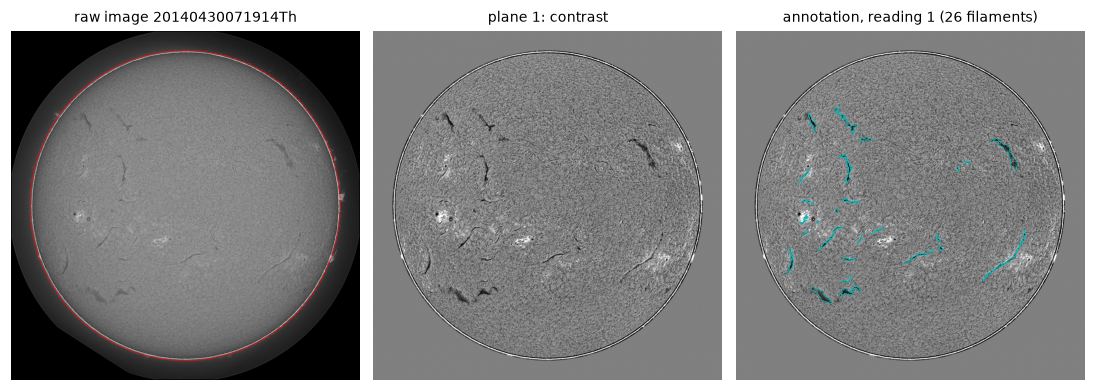

In [4]:
stem = max(by_stem, key=lambda s: len(by_stem[s][0].rles()))
img = D.load_image(stem, "train", DATA_ROOT)
planes, disk = flat_field(img, clip=0.5)
gt = np.zeros(img.shape, bool)
for r in by_stem[stem][0].rles():
    gt |= mu.decode(r).astype(bool)

fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
ax[0].imshow(img, cmap="gray"); ax[0].set_title(f"raw image {stem}")
ax[0].add_patch(plt.Circle((disk.cx, disk.cy), disk.r, fill=False, color="r", lw=0.6, ls="--"))
ax[1].imshow(planes[0], cmap="gray", vmin=-0.3, vmax=0.3); ax[1].set_title("plane 1: contrast")
ax[2].imshow(planes[0], cmap="gray", vmin=-0.3, vmax=0.3); ax[2].contour(gt, [0.5], colors="c", linewidths=0.4)
ax[2].set_title(f"annotation, reading 1 ({len(by_stem[stem][0].rles())} filaments)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Training

Each model trains on 4 folds and predicts the held-out fold (out-of-fold map, 4-way TTA).
Training uses random 512 px crops of the full-resolution image. The target is the mean of the annotator readings.
The best epoch is chosen by validation PQ. The BiCC loss (Bouteille et al., 2026) adds a per-component term that
penalises missed and spurious filaments.

In [5]:
if TRAIN == "full":
    for fam in P.FAMILIES:
        for k in range(5):
            P.train_fold(fam, k, WEIGHTS / fam / f"f{k}", SPLITS, DATA_ROOT, WORKERS)
    n = P.blend_oof([WEIGHTS / "b3" / f"f{k}" / "oof" for k in range(5)],
                    [WEIGHTS / "bicc" / f"f{k}" / "oof" for k in range(5)], OOF_BLEND)
    print("blended out-of-fold maps:", n)
else:
    if TRAIN == "smoke":
        P.train_fold("bicc", 0, OUT / "smoke_train", SPLITS, DATA_ROOT, WORKERS, smoke=True)
    if not (WEIGHTS / "bicc/f4/best.pth").exists():
        P.fetch_release(RELEASE_URL, RELEASE)

models = pd.DataFrame([dict(family=fam, fold=k, **{m: json.load(open(WEIGHTS / fam / f"f{k}" / "final.json"))["oof_tta4"][m]
                                                  for m in ("pq", "tp", "fp", "fn")})
                       for fam in P.FAMILIES for k in range(5)])
print("held-out PQ per model (default rule post-processing):")
models.pivot(index="fold", columns="family", values="pq").round(4).assign(diff=lambda d: (d.bicc - d.b3).round(4))

held-out PQ per model (default rule post-processing):


family,b3,bicc,diff
fold,,,
0,0.4375,0.4455,0.0080
1,0.4328,0.4380,0.0052
2,0.4145,0.4375,0.0230
3,0.4153,0.4288,0.0135
4,0.4138,0.4119,-0.0019


## 5. Post-processing: candidates, rescorer and core rule

1. **Candidates.** Hysteresis thresholds 0.5 / 0.3 on the blended map, then join parts closer than 8 px. This step keeps almost everything.
2. **Rescorer.** A gradient-boosted regressor predicts each candidate's PQ gain (mean over readings of IoU when IoU > 0.5) from 16
   features of the probability map only (size, shape, probability statistics, position on the disk). A candidate is kept if the
   predicted gain is above τ. τ maximises pooled PQ on stem-grouped out-of-fold predictions.
3. **Core rule.** Each kept filament keeps only its pixels with p > 0.5. The low threshold is needed to connect filament parts,
   but it also adds a faint border that makes the masks about 6 % too wide.

The rescorer is fitted on the out-of-fold maps, so it never sees a prediction on its own training image.

In [6]:
oof_stems = sorted(s for s in by_stem if P.map_path(OOF_BLEND, s))
t0 = time.time()
cands, n_gt = P.extract_candidates(OOF_BLEND, DATA_ROOT, by_stem, oof_stems, WORKERS)
bundle, curve = P.fit_rescorer(cands, n_gt)
print(f"{len(cands)} candidates from {len(oof_stems)} images ({time.time() - t0:.0f} s); tau = {bundle['tau']:.2f}")
print("pooled PQ of the kept candidates (stem-grouped OOF):", curve.loc[[0.0, 0.1, 0.2, bundle["tau"], 0.4, 0.5]].round(4).to_dict())

6602 candidates from 707 images (172 s); tau = 0.25
pooled PQ of the kept candidates (stem-grouped OOF): {0.0: 0.4117, 0.1: 0.4315, 0.2: 0.4458, 0.25: 0.4478, 0.4: 0.42, 0.5: 0.3499}


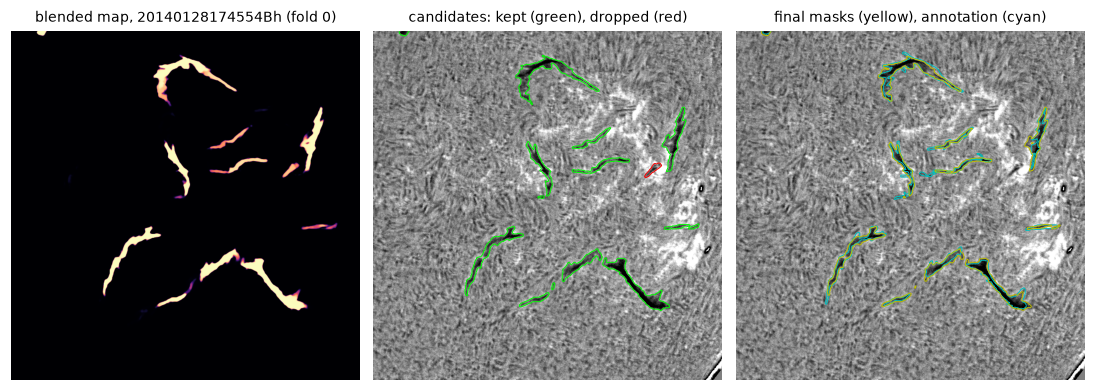

In [7]:
# one validation image: blended out-of-fold map, candidates kept / dropped, final masks against one reading
s = max((x for x in oof_stems if splits[x] == 0), key=lambda x: len(by_stem[x][0].rles()))
p = P.load_map(P.map_path(OOF_BLEND, s))
rr = radius_map(p.shape, fit_disk(D.load_image(s, "train", DATA_ROOT)))
cand = instances(p, PPConfig(**bundle["permissive"]), rr)
final = P.final_labels(p, rr, bundle)
kept = np.isin(cand, np.unique(cand[final > 0])) & (cand > 0)
g = np.zeros(p.shape, bool)
for r in by_stem[s][0].rles():
    g |= mu.decode(r).astype(bool)
ys, xs = np.nonzero(g); cy, cx = int(np.median(ys)), int(np.median(xs))
win = (slice(max(cy - 350, 0), cy + 350), slice(max(cx - 350, 0), cx + 350))

c = flat_field(D.load_image(s, "train", DATA_ROOT), clip=0.5)[0][0]
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
ax[0].imshow(p[win], cmap="magma", vmin=0, vmax=1); ax[0].set_title(f"blended map, {s} (fold 0)")
ax[1].imshow(c[win], cmap="gray", vmin=-0.3, vmax=0.3)
ax[1].contour(kept[win], [0.5], colors="lime", linewidths=0.6); ax[1].contour(((cand > 0) & ~kept)[win], [0.5], colors="r", linewidths=0.6)
ax[1].set_title("candidates: kept (green), dropped (red)")
ax[2].imshow(c[win], cmap="gray", vmin=-0.3, vmax=0.3)
ax[2].contour(g[win], [0.5], colors="c", linewidths=0.6); ax[2].contour((final > 0)[win], [0.5], colors="y", linewidths=0.6)
ax[2].set_title("final masks (yellow), annotation (cyan)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 6. Cross-validation

Pooled PQ over all 1,154 readings of the 707 training images, computed exactly as the official metric (TP if IoU > 0.5).
For each fold, the rescorer is refitted without that fold. The 95 % interval is an image bootstrap (2,000 draws).

In [8]:
cv, cv_rows = P.cross_validate(OOF_BLEND, DATA_ROOT, by_stem, splits, cands, bundle, oof_stems, WORKERS)
pd.DataFrame([{"PQ": round(cv["pq"], 4), "95 % CI": cv["ci95"], "SQ": round(cv["sq"], 4), "TP": cv["tp"], "FP": cv["fp"], "FN": cv["fn"],
               **{f"fold {k}": v for k, v in cv["per_fold"].items()}}], index=["B3 + BiCC blend, rescorer, core rule"])

,PQ,95 % CI,SQ,TP,FP,FN,fold 0,fold 1,fold 2,fold 3,fold 4
"B3 + BiCC blend, rescorer, core rule",0.4519,"[0.4426, 0.4611]",0.6846,5092,2135,3107,0.4585,0.4609,0.4536,0.4437,0.4429


## 7. Test inference and submission

Every test image goes through the same steps: preprocessing, 10 models with TTA, blend, candidates, rescorer, core rule.
The submission has one row per filament: `filament_id` (`<image>_<index>`) and `segmentation_rle` (COCO compressed RLE).
The masks of one image never overlap.

In [ ]:
b3_models = load_runs(str(WEIGHTS / "b3" / "f*"), "best", DEVICE)
bicc_models = load_runs(str(WEIGHTS / "bicc" / "f*"), "best", DEVICE)
assert len(b3_models) == 5 and len(bicc_models) == 5

stems = test_stems[:N_TEST] if N_TEST else test_stems
rows, labels, t0 = [], {}, time.time()
for i, s in enumerate(stems):
    img = D.load_image(s, "test", DATA_ROOT)
    p, disk = P.blend_map(b3_models, bicc_models, img, DEVICE, TTA)
    labels[s] = P.final_labels(p, radius_map(p.shape, disk), bundle)
    rows += RL.labels_to_rows(s, labels[s])
    if i % 20 == 0 or i == len(stems) - 1:
        print(f"{i + 1}/{len(stems)} images, {len(rows)} filaments, {time.time() - t0:.0f} s")

SUB = OUT / "submission.csv"
RL.write_csv(rows, SUB)
check = RL.validate_csv(SUB, set(stems))
assert check["n_errors"] == 0, check
print(SUB, check)

In [ ]:
fig, ax = plt.subplots(1, min(3, len(stems)), figsize=(10, 3.6), squeeze=False)
for a, s in zip(ax[0], stems):
    lab = labels[s]
    a.imshow(D.load_image(s, "test", DATA_ROOT), cmap="gray")
    a.imshow(np.ma.masked_equal(lab, 0), cmap="tab20", interpolation="nearest", alpha=0.8)
    a.set_title(f"{s}: {lab.max()} filaments"); a.axis("off")
plt.tight_layout(); plt.show()

## 8. Reproduction check

The submitted file (`data/fsc26_final_submission.csv`, public leaderboard PQ 0.40) is compared, mask by mask, with the
masks made above.

In [ ]:
ref = RL.read_csv(REPO / "data/fsc26_final_submission.csv")
ious = []
for s in stems:
    a = [RL.to_rle(c) for c in ref.get(s, [])]
    b = [mu.encode(np.asfortranarray((labels[s] == k).astype(np.uint8))) for k in range(1, labels[s].max() + 1)]
    if a and b:
        ious += np.asarray(mu.iou(b, a, [0] * len(a))).max(1).tolist()
    assert len(a) == len(b), (s, len(a), len(b))
print(f"{len(stems)} images, {len(ious)} filaments, mask IoU with the submitted file: min {min(ious):.4f}, mean {np.mean(ious):.4f}")